# Movie Review Sentiment Analysis

## Project Overview
This project uses Machine Learning and Natural Language Processing (NLP) to classify movie reviews as Positive or Negative.

## Objectives
- Understand and preprocess text data.
- Convert text into numerical features using TF-IDF.
- Train Logistic Regression and Multinomial Naive Bayes models.
- Compare model performance.
- Predict sentiment for new movie reviews.

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- Google Colab

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
import nltk
from nltk.corpus import movie_reviews

# Download the movie reviews dataset
nltk.download('movie_reviews')

# Extract review text and sentiment labels
reviews = []
sentiments = []

for fileid in movie_reviews.fileids():
    review = movie_reviews.raw(fileid)
    sentiment = movie_reviews.categories(fileid)[0]

    reviews.append(review)
    sentiments.append(sentiment)

# Create a DataFrame
df = pd.DataFrame({
    'Review': reviews,
    'Sentiment': sentiments
})

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nSentiment distribution:")
print(df['Sentiment'].value_counts())

df.head()

[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.


Dataset loaded successfully!
Dataset shape: (2000, 2)

Sentiment distribution:
Sentiment
neg    1000
pos    1000
Name: count, dtype: int64


,Review,Sentiment
0,"plot : two teen couples go to a church party ,...",neg
1,the happy bastard's quick movie review \ndamn ...,neg
2,it is movies like these that make a jaded movi...,neg
3,""" quest for camelot "" is warner bros . ' firs...",neg
4,synopsis : a mentally unstable man undergoing ...,neg


In [3]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check for duplicate reviews
print("\nDuplicate Reviews:", df.duplicated().sum())

# Display one positive and one negative review
print("\nPositive Review:")
print(df[df['Sentiment'] == 'pos']['Review'].iloc[0][:500])

print("\nNegative Review:")
print(df[df['Sentiment'] == 'neg']['Review'].iloc[0][:500])

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Review     2000 non-null   object
 1   Sentiment  2000 non-null   object
dtypes: object(2)
memory usage: 31.4+ KB

Missing Values:
Review       0
Sentiment    0
dtype: int64

Duplicate Reviews: 0

Positive Review:
films adapted from comic books have had plenty of success , whether they're about superheroes ( batman , superman , spawn ) , or geared toward kids ( casper ) or the arthouse crowd ( ghost world ) , but there's never really been a comic book like from hell before . 
for starters , it was created by alan moore ( and eddie campbell ) , who brought the medium to a whole new level in the mid '80s with a 12-part series called the watchmen . 
to say moore and campbell thoroughly researched the subject

Negative Review:
plot : two teen couples go to a church party , drink and 

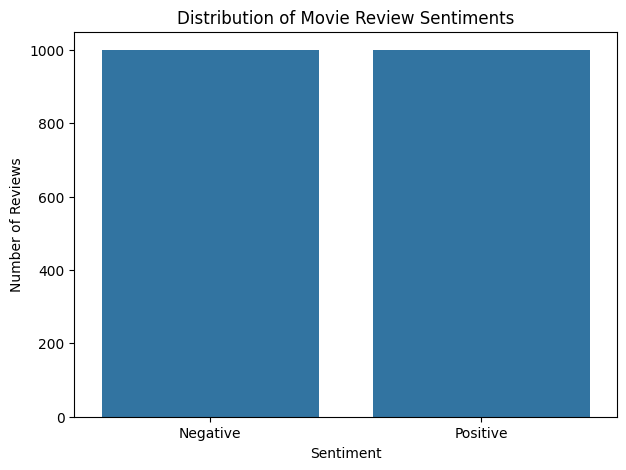

In [4]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Sentiment')

plt.title('Distribution of Movie Review Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.xticks([0, 1], ['Negative', 'Positive'])

plt.savefig('sentiment_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [5]:
# Convert sentiment labels into numerical values
df['Sentiment_Label'] = df['Sentiment'].map({
    'neg': 0,
    'pos': 1
})

# Check the converted labels
print(df[['Sentiment', 'Sentiment_Label']].head(10))

print("\nLabel conversion completed!")

  Sentiment  Sentiment_Label
0       neg                0
1       neg                0
2       neg                0
3       neg                0
4       neg                0
5       neg                0
6       neg                0
7       neg                0
8       neg                0
9       neg                0

Label conversion completed!


In [6]:
# Separate reviews and sentiment labels
X = df['Review']
y = df['Sentiment_Label']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))
print("\nData splitting completed!")

Training data: 1600
Testing data: 400

Data splitting completed!


In [7]:
# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    ngram_range=(1, 2)
)

# Fit on training data and transform both datasets
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training data shape: (1600, 10000)
Testing data shape: (400, 10000)


In [8]:
# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

# Train Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [9]:
# Predict using both models
lr_predictions = lr_model.predict(X_test_tfidf)
nb_predictions = nb_model.predict(X_test_tfidf)

print("Predictions completed!")

print("\nLogistic Regression Predictions:")
print(lr_predictions[:10])

print("\nNaive Bayes Predictions:")
print(nb_predictions[:10])

Predictions completed!

Logistic Regression Predictions:
[0 0 1 1 0 1 1 0 0 1]

Naive Bayes Predictions:
[0 0 1 1 0 1 1 0 0 1]


In [10]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

# Calculate Logistic Regression metrics
lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions)
lr_recall = recall_score(y_test, lr_predictions)
lr_f1 = f1_score(y_test, lr_predictions)

# Calculate Naive Bayes metrics
nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_precision = precision_score(y_test, nb_predictions)
nb_recall = recall_score(y_test, nb_predictions)
nb_f1 = f1_score(y_test, nb_predictions)

# Create comparison table
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Multinomial Naive Bayes'],
    'Accuracy': [lr_accuracy, nb_accuracy],
    'Precision': [lr_precision, nb_precision],
    'Recall': [lr_recall, nb_recall],
    'F1 Score': [lr_f1, nb_f1]
})

print(results.round(4))

                     Model  Accuracy  Precision  Recall  F1 Score
0      Logistic Regression    0.8300     0.8143   0.855    0.8341
1  Multinomial Naive Bayes    0.8025     0.8071   0.795    0.8010


In [11]:
print("LOGISTIC REGRESSION REPORT")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=['Negative', 'Positive']
))

print("\nNAIVE BAYES REPORT")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=['Negative', 'Positive']
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

    Negative       0.85      0.81      0.83       200
    Positive       0.81      0.85      0.83       200

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400


NAIVE BAYES REPORT
              precision    recall  f1-score   support

    Negative       0.80      0.81      0.80       200
    Positive       0.81      0.80      0.80       200

    accuracy                           0.80       400
   macro avg       0.80      0.80      0.80       400
weighted avg       0.80      0.80      0.80       400



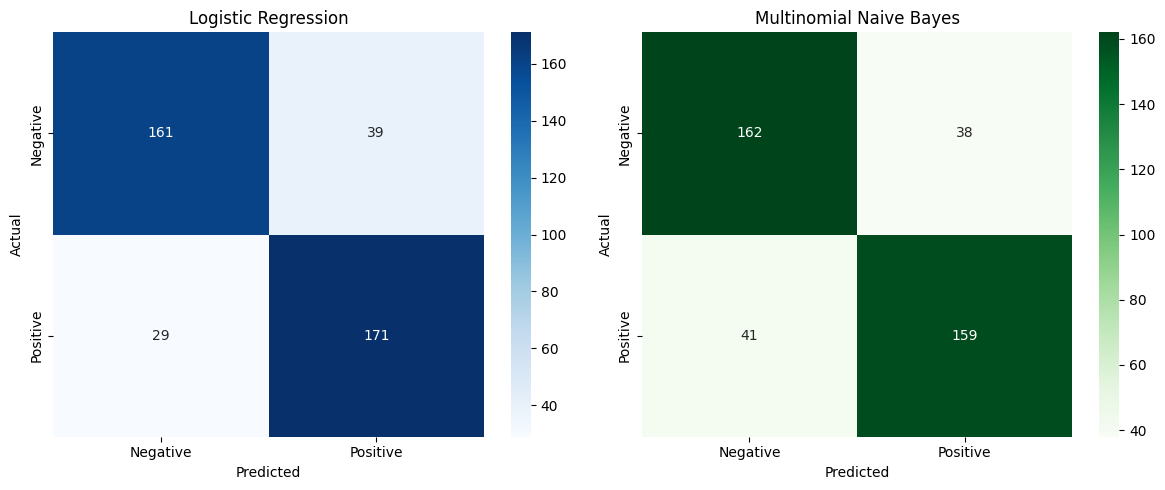

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
cm_lr = confusion_matrix(y_test, lr_predictions)

sns.heatmap(
    cm_lr, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'],
    ax=axes[0]
)

axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Naive Bayes
cm_nb = confusion_matrix(y_test, nb_predictions)

sns.heatmap(
    cm_nb, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'],
    ax=axes[1]
)

axes[1].set_title('Multinomial Naive Bayes')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

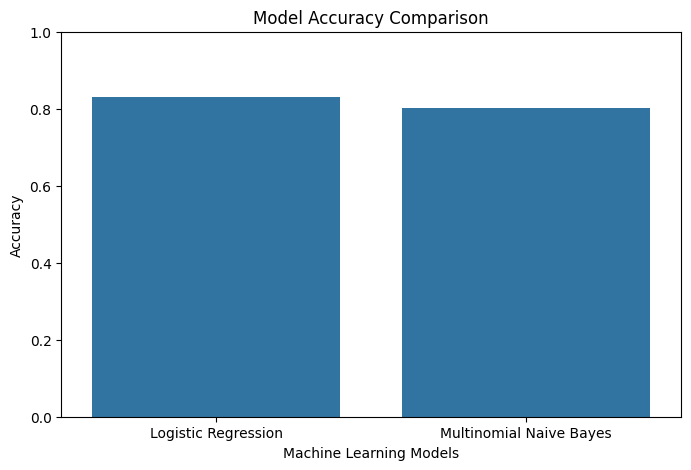

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

plt.savefig('model_accuracy_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [14]:
# Sample movie reviews
sample_reviews = [
    "This movie was amazing. The acting and story were excellent.",
    "The movie was boring and disappointing. I did not enjoy it.",
    "Fantastic movie with wonderful performances and beautiful scenes.",
    "Worst movie ever. The story was terrible and acting was poor."
]

# Convert reviews using the trained TF-IDF vectorizer
sample_tfidf = tfidf.transform(sample_reviews)

# Predict sentiments
sample_predictions = lr_model.predict(sample_tfidf)

# Display predictions
for review, prediction in zip(sample_reviews, sample_predictions):

    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 60)

Review: This movie was amazing. The acting and story were excellent.
Predicted Sentiment: Positive
------------------------------------------------------------
Review: The movie was boring and disappointing. I did not enjoy it.
Predicted Sentiment: Negative
------------------------------------------------------------
Review: Fantastic movie with wonderful performances and beautiful scenes.
Predicted Sentiment: Positive
------------------------------------------------------------
Review: Worst movie ever. The story was terrible and acting was poor.
Predicted Sentiment: Negative
------------------------------------------------------------


In [15]:
import joblib
from sklearn.pipeline import Pipeline

# Select the better model based on F1 score
if lr_f1 >= nb_f1:
    best_model_name = "Logistic Regression"
    best_classifier = LogisticRegression(max_iter=1000)
else:
    best_model_name = "Multinomial Naive Bayes"
    best_classifier = MultinomialNB()

# Create complete pipeline
best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        max_features=10000,
        ngram_range=(1, 2)
    )),
    ('classifier', best_classifier)
])

# Train pipeline on raw text
best_pipeline.fit(X_train, y_train)

# Save pipeline
joblib.dump(best_pipeline, 'sentiment_analysis_model.pkl')

print("Best Model:", best_model_name)
print("Model pipeline saved successfully!")

Best Model: Logistic Regression
Model pipeline saved successfully!


In [16]:
# Load saved model
loaded_model = joblib.load('sentiment_analysis_model.pkl')

# Test a new review
new_review = [
    "The movie was excellent and I really loved it."
]

prediction = loaded_model.predict(new_review)

if prediction[0] == 1:
    print("Predicted Sentiment: Positive")
else:
    print("Predicted Sentiment: Negative")

Predicted Sentiment: Positive


In [17]:
from google.colab import files

files.download('sentiment_distribution.png')
files.download('confusion_matrices.png')
files.download('model_accuracy_comparison.png')
files.download('sentiment_analysis_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>